In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from PIL import ImageEnhance
from sklearn import model_selection

In [2]:
DATASET_PATH = r"C:\Users\emanu\PycharmProjects\NAML_project_AA_2025-2026\archive\chest_xray\train"
IMG_SIZE = (128, 128)

categories = [d for d in os.listdir(DATASET_PATH) if os.path.isdir(os.path.join(DATASET_PATH, d))]
categories.sort()

print(f"Classes found: {categories}")

data = []
labels = []

for category in categories:
    path = os.path.join(DATASET_PATH, category)
    class_num = categories.index(category)

    print(f"Loading class '{category}' with label {class_num}...")

    for img_name in os.listdir(path):
        img_path = os.path.join(path, img_name)
        img = Image.open(img_path)
        img = img.convert('RGB')
        img = img.resize(IMG_SIZE)
        img_array = np.array(img)
        data.append(img_array)
        labels.append(class_num)

X = np.array(data)
X = X.transpose(0, 3, 1, 2)
y = np.array(labels)

perm = np.random.permutation(len(X))
X = X[perm]
y = y[perm]

print(f"\nShape X (Images): {X.shape}")
print(f"Shape y (Labels):   {y.shape}")

Classes found: ['NORMAL', 'PNEUMONIA']
Loading class 'NORMAL' with label 0...
Loading class 'PNEUMONIA' with label 1...

Shape X (Images): (5232, 3, 128, 128)
Shape y (Labels):   (5232,)


In [3]:
output_folder = r"C:\Users\emanu\PycharmProjects\NAML_project_AA_2025-2026\preprocessed_dataset"
filename = "dataset.npz"
full_path = os.path.join(output_folder, filename)
np.savez_compressed(full_path,
                    X=X,
                    y=y)

print(f"File saved in: {full_path}")

File saved in: C:\Users\emanu\PycharmProjects\NAML_project_AA_2025-2026\preprocessed_dataset\dataset.npz


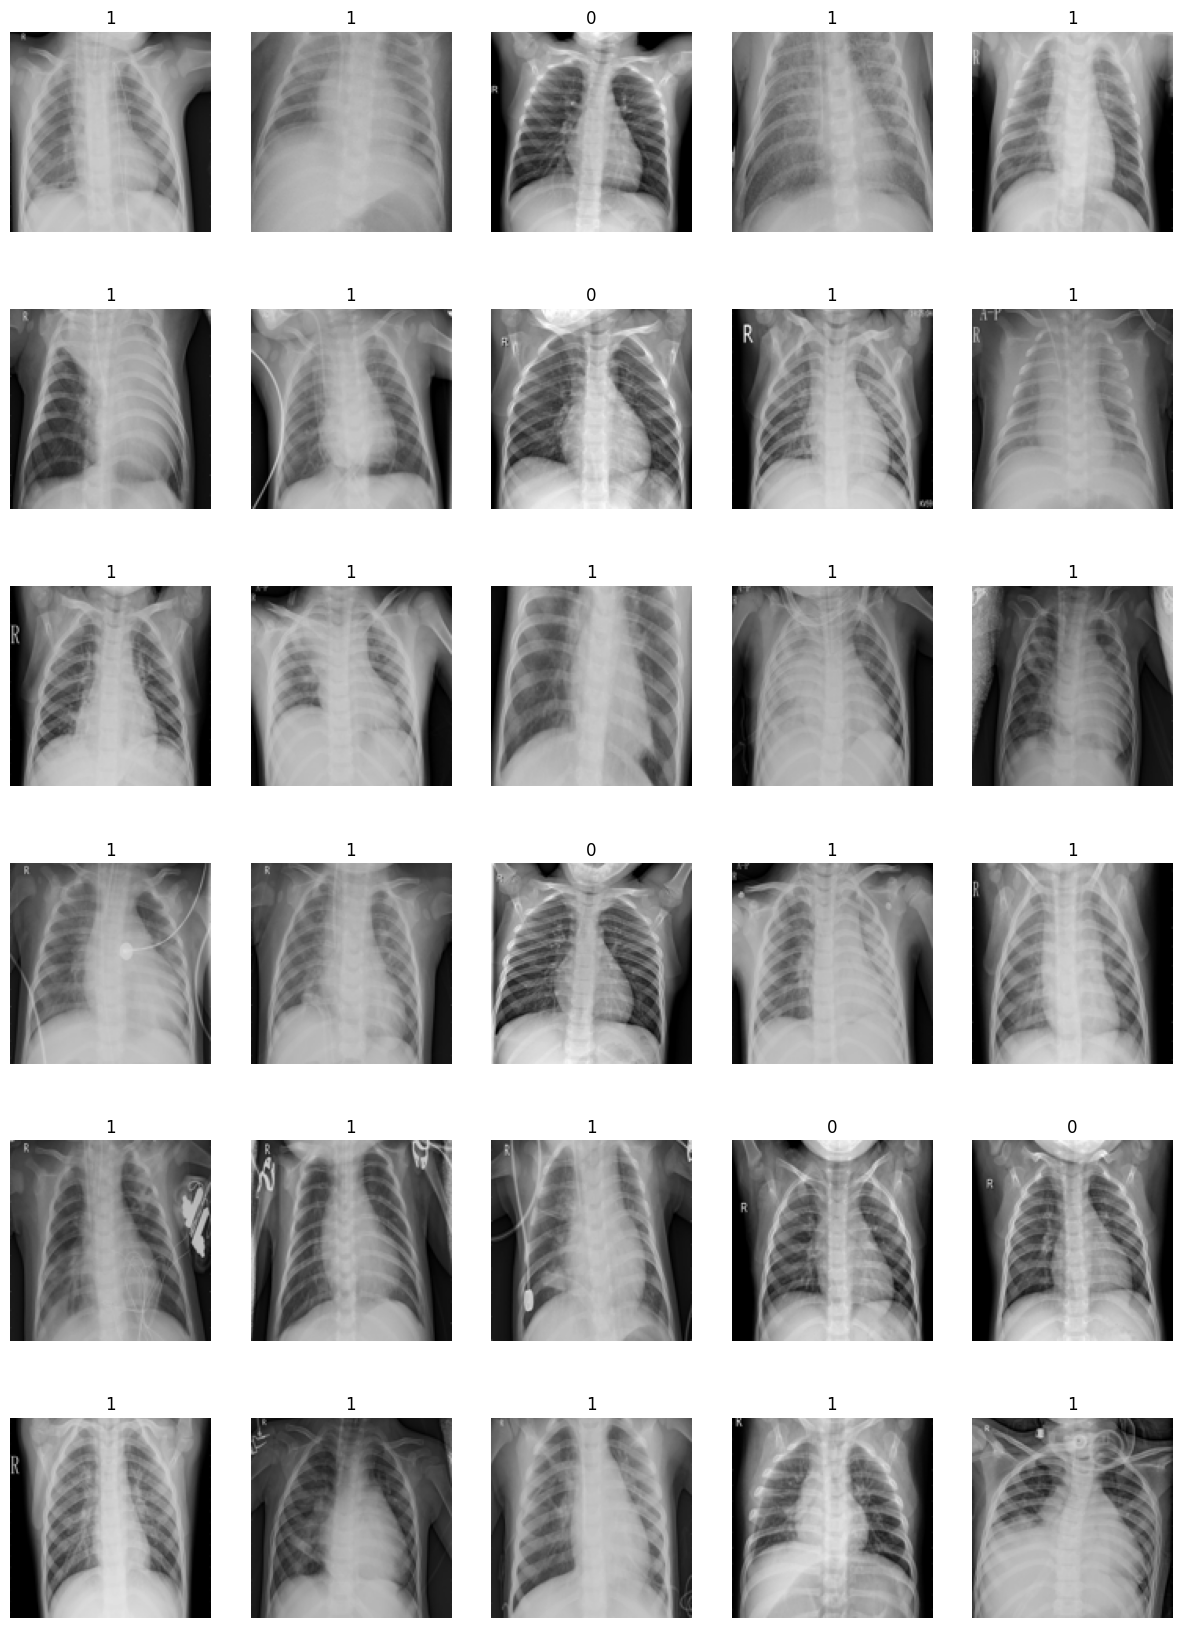

In [20]:
n = 30
rows = 6
cols = 5
vmin = 0
vmax = 255
fig, axs = plt.subplots(rows,cols,figsize=(15, 3.5 * rows))
axs = axs.flatten()
for i in range(n):
    axs[i].set_title(f"{y[i]}")
    axs[i].imshow(X[i].transpose(1, 2, 0))
    axs[i].axis("off")